# floway walkthrough

One FCS file, start to finish: parse it, work out which detector is which, gate
cells and singlets, and read out a fluorescence distribution.

`example.fcs` sits beside this notebook — one transfected well read on an Attune,
GFP on BL1-A and mCherry on YL2-A.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import floway
from floway import FCSParser, PlateGate, detect_channels, find_channel, plot_kde

EXAMPLE = "example.fcs"
print("floway", floway.__version__)

parser = FCSParser(EXAMPLE)
events = parser.get_data()
print(f"{len(events):,} events x {events.shape[1]} channels")

floway 0.1.0


23,273 events x 30 channels


## Which detector is which

`list_channels()` reports what the file says. `detect_channels()` adds a guess at
what each fluorescence channel is for, so you can ask for a fluorophore by name
instead of memorising that this machine calls GFP `BL1-A`.

In [2]:
channels = detect_channels(parser)
display(channels[channels.kind == "fluorescence"].head(6))

GFP = find_channel(parser, "GFP")
MCHERRY = find_channel(parser, "mCherry")
print(f"GFP -> {GFP}   mCherry -> {MCHERRY}")

,column,kind,stain,color,fluorophore_guess,laser_nm,emission_nm,confidence
4,BL1-A,fluorescence,BL1-A,green,GFP/FITC,488.0,530.0,low
5,BL2-A,fluorescence,BL2-A,yellow,PE,488.0,590.0,low
6,BL3-A,fluorescence,BL3-A,red,PerCP-Cy5.5,488.0,695.0,low
7,YL2-A,fluorescence,YL2-A,orange-red,mCherry,561.0,620.0,low
8,YL1-A,fluorescence,YL1-A,yellow,PE,561.0,585.0,low
9,VL2-A,fluorescence,VL2-A,green,BV510,405.0,512.0,low


GFP -> BL1-A   mCherry -> YL2-A


## Gating: two cuts, one fit

`PlateGate` fits once and applies that one gate to every well of a run. Here there
is a single well, so the list has one entry — but pass the whole plate whenever you
have it, because a gate fitted per well drifts and on a weak sample can mis-call it
entirely.

Three steps, in order:

1. events pinned at the detector ceiling are dropped — their pulse area is clipped,
   which would break step 3;
2. **cells vs debris**, from a 2-component Gaussian mixture on log10(FSC-A, SSC-A);
3. **singlets vs doublets**, from the valley in log10(FSC-A / FSC-H).

The two cuts stay separately reachable afterwards, which is what lets you draw them:
`gate.cells(df)` is step 2 alone, `gate.ratio_cut` is the line of step 3, and
`gate.apply(df)` is both together.

In [3]:
gate = PlateGate.fit([EXAMPLE])
print(gate, "\n")

cells = gate.cells(events)          # step 2 on its own
singlets = gate.apply(events)       # steps 2 and 3 together
print(f"  cells    {cells.sum():>7,} of {len(events):,} events ({cells.mean():.0%})")
print(f"  singlets {singlets.sum():>7,} of {cells.sum():,} cells "
      f"({singlets.sum() / cells.sum():.0%})")

display(gate.summary([EXAMPLE], labels=["example"]))

PlateGate(fit on 5,000 events; cells at log10 FSC/SSC [5.74, 5.45], posterior>0.5; FSC-A/FSC-H cut 2.23 between modes 1.69 and 2.24) 

  cells     17,859 of 23,273 events (77%)
  singlets  13,528 of 17,859 cells (76%)


,source,events,saturated,debris,cells,doublets,singlets,pct_saturated,pct_cells,pct_singlets_of_cells,pct_singlets
0,example,23273,3675,1739,17859,4331,13528,15.790831,76.736991,75.748922,58.127444


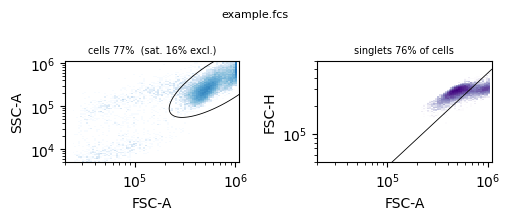

In [4]:
# Both cuts drawn: the cell boundary on FSC-A/SSC-A, then the singlet line on
# FSC-A/FSC-H. gate.gmm, gate.cell_component and gate.ratio_cut are public, so a
# figure can redraw either boundary in its own style.
gate.plot(EXAMPLE, title="example.fcs")
plt.show()

## Reading out fluorescence

The well carries an mCherry-marked effector, so the cells that received it are the
ones worth scoring. Their GFP against the rest of the singlets is the whole readout.

mCherry+ 4,997 of 13,528 singlets (36.9%)
median GFP   mCherry+    25,463   mCherry-       471


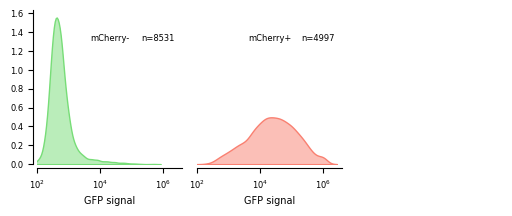

In [5]:
MCHERRY_GATE = 5e3      # YL2-A above this = received the effector

gated = events[singlets]
transfected = gated[MCHERRY] > MCHERRY_GATE
print(f"mCherry+ {transfected.sum():,} of {len(gated):,} singlets ({transfected.mean():.1%})")
print(f"median GFP   mCherry+ {np.median(gated.loc[transfected, GFP]):>9,.0f}"
      f"   mCherry- {np.median(gated.loc[~transfected, GFP]):>9,.0f}")

long = pd.DataFrame({
    "GFP_signal": gated[GFP].clip(lower=1),
    "sample": np.where(transfected, "mCherry+", "mCherry-"),
})
plot_kde(long, unique_conds=["mCherry-", "mCherry+"], count=True)